In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress

%matplotlib qt
import mne

MNE is an open source python package made for exploring, visualizing, and analyzing human neurophysiological data: MEG, EEG, sEEG, ECoG, NIRS, and more. [link to mne documentation](https://mne.tools/stable/index.html)

Ignorer MaxFilter signifie pas de SSS, pas de tSSS, pas de compensation du champ externe, pas de correction du mouvement. 

Donc OK pour analyses simples (PSD, time-frequency, ICA exploratoire) mais pas idéal pour source reconstruction ou analyses fines de topographie

In [25]:
raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/run01.fif", preload=True, allow_maxshield=True)

Opening raw data file /Users/elodiehusson/Desktop/run01.fif...
    Read a total of 13 projection items:
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle


/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_59727/126410303.py:1: RuntimeWarning: This filename (/Users/elodiehusson/Desktop/run01.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/run01.fif", preload=True, allow_maxshield=True)


    Range : 529000 ... 912999 =    529.000 ...   912.999 secs
Ready.
Reading 0 ... 383999  =      0.000 ...   383.999 secs...


/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_59727/126410303.py:1: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/run01.fif", preload=True, allow_maxshield=True)


From the raw object, we can see that there are 306 data channels : 102 are magnetometers, and 204 are gradiometers. This is a normal protocol for MEG, we have 1 magn and 2 gradio for each position. So we have triplets. Sampling rate is at 1000 Hz, which is a normal rate : it give a good temporal resolution for the ERF / time-frequency. 

In [16]:
raw.info

<Info | 27 non-empty values
 acq_pars: ACQactiveGround 0 ACQch.BIO001.gain 2000 ACQch.BIO001.highpass ...
 bads: 1 items (MEG0113)
 ch_names: BIO001, BIO002, BIO003, EXCI, IASX+, IASX-, IASY+, IASY-, IASZ+, ...
 chs: 3 BIO, 1 Flux excitation channel, 11 Internal Active Shielding data (Triux systems), 102 Magnetometers, 204 Gradiometers, 5 misc, 1 Stimulus, 1 System status channel information (Triux systems)
 custom_ref_applied: False
 description: TRIUX system at LaPitie
 dev_head_t: MEG device -> head transform
 dig: 231 items (3 Cardinal, 4 HPI, 224 Extra)
 events: 1 item (list)
 experimenter: Common User (acq)
 file_id: 4 items (dict)
 gantry_angle: 68.0
 highpass: 0.0 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 hpi_subsystem: 3 items (dict)
 line_freq: 50.0
 lowpass: 330.0 Hz
 maxshield: True
 meas_date: 2026-02-25 13:43:04 UTC
 meas_id: 4 items (dict)
 nchan: 328
 proc_history: 1 item (list)
 proj_id: 110
 proj_name: frint
 projs: generated with dossp-2.1: off, generated with dossp-2.1: off, ...
 sfreq: 1000.0 Hz
 subject_info: <subject_info | id: 1777, last_name: frint_pilote, first_name: p, birthday: 1980-01-01, sex: 1, hand: 1>
>

In [26]:
mne.channel_indices_by_type(raw.info)

{'eeg': [],
 'csd': [],
 'stim': [326],
 'eog': [],
 'ecg': [],
 'emg': [],
 'misc': [321, 322, 323, 324, 325],
 'resp': [],
 'chpi': [],
 'exci': [3],
 'ias': [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 'syst': [327],
 'seeg': [],
 'dipole': [],
 'gof': [],
 'bio': [0, 1, 2],
 'ecog': [],
 'dbs': [],
 'temperature': [],
 'gsr': [],
 'ref_meg': [],
 'mag': [15,
  18,
  21,
  24,
  27,
  30,
  33,
  36,
  39,
  42,
  45,
  48,
  51,
  54,
  57,
  60,
  63,
  66,
  69,
  72,
  75,
  78,
  81,
  84,
  87,
  90,
  93,
  96,
  99,
  102,
  105,
  108,
  111,
  114,
  117,
  120,
  123,
  126,
  129,
  132,
  135,
  138,
  141,
  144,
  147,
  150,
  153,
  156,
  159,
  162,
  165,
  168,
  171,
  174,
  177,
  180,
  183,
  186,
  189,
  192,
  195,
  198,
  201,
  204,
  207,
  210,
  213,
  216,
  219,
  222,
  225,
  228,
  231,
  234,
  237,
  240,
  243,
  246,
  249,
  252,
  255,
  258,
  261,
  264,
  267,
  270,
  273,
  276,
  279,
  282,
  285,
  288,
  291,
  294,
  297,
  300,
  

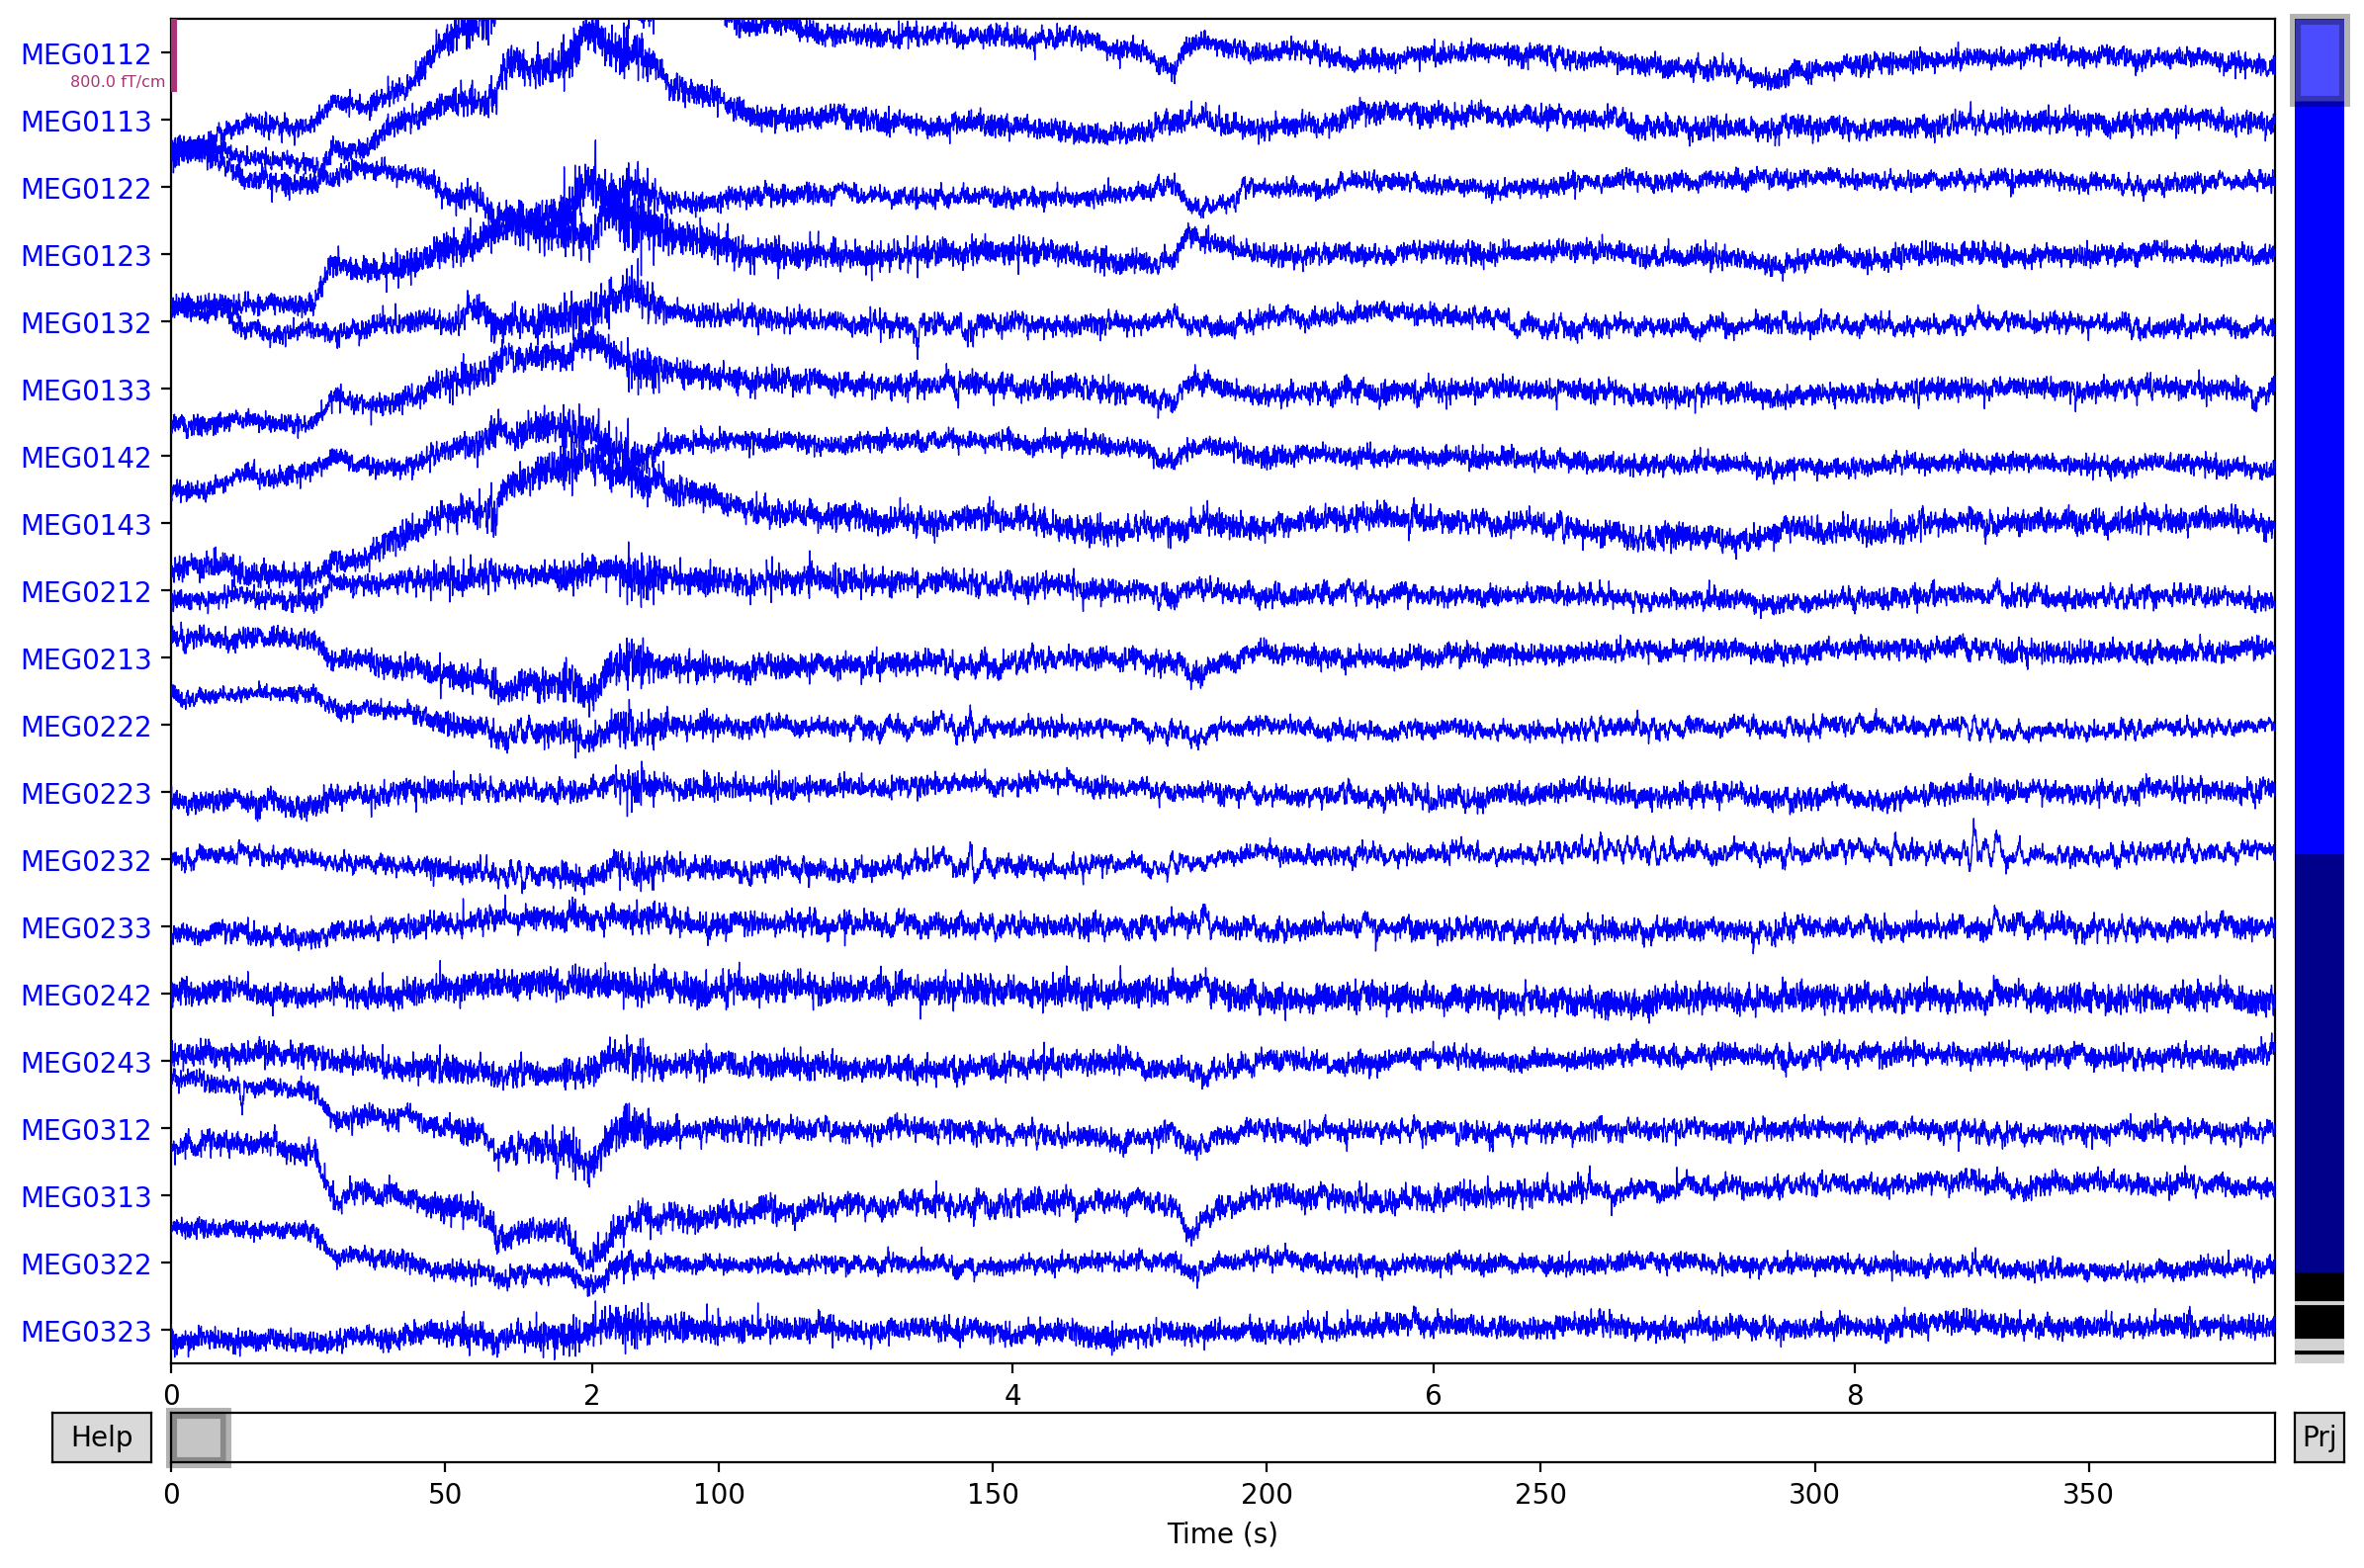

Channels marked as bad:
['IAS_Y', 'IAS_Z', 'SYS201', 'BIO002', 'BIO003', 'IASX+', 'MISC009', 'MISC008', 'MISC002', 'IASX-', 'BIO001', 'MEG2511']


In [51]:
raw.plot()

Effective window size : 2.048 (s)
Plotting power spectral density (dB=True).


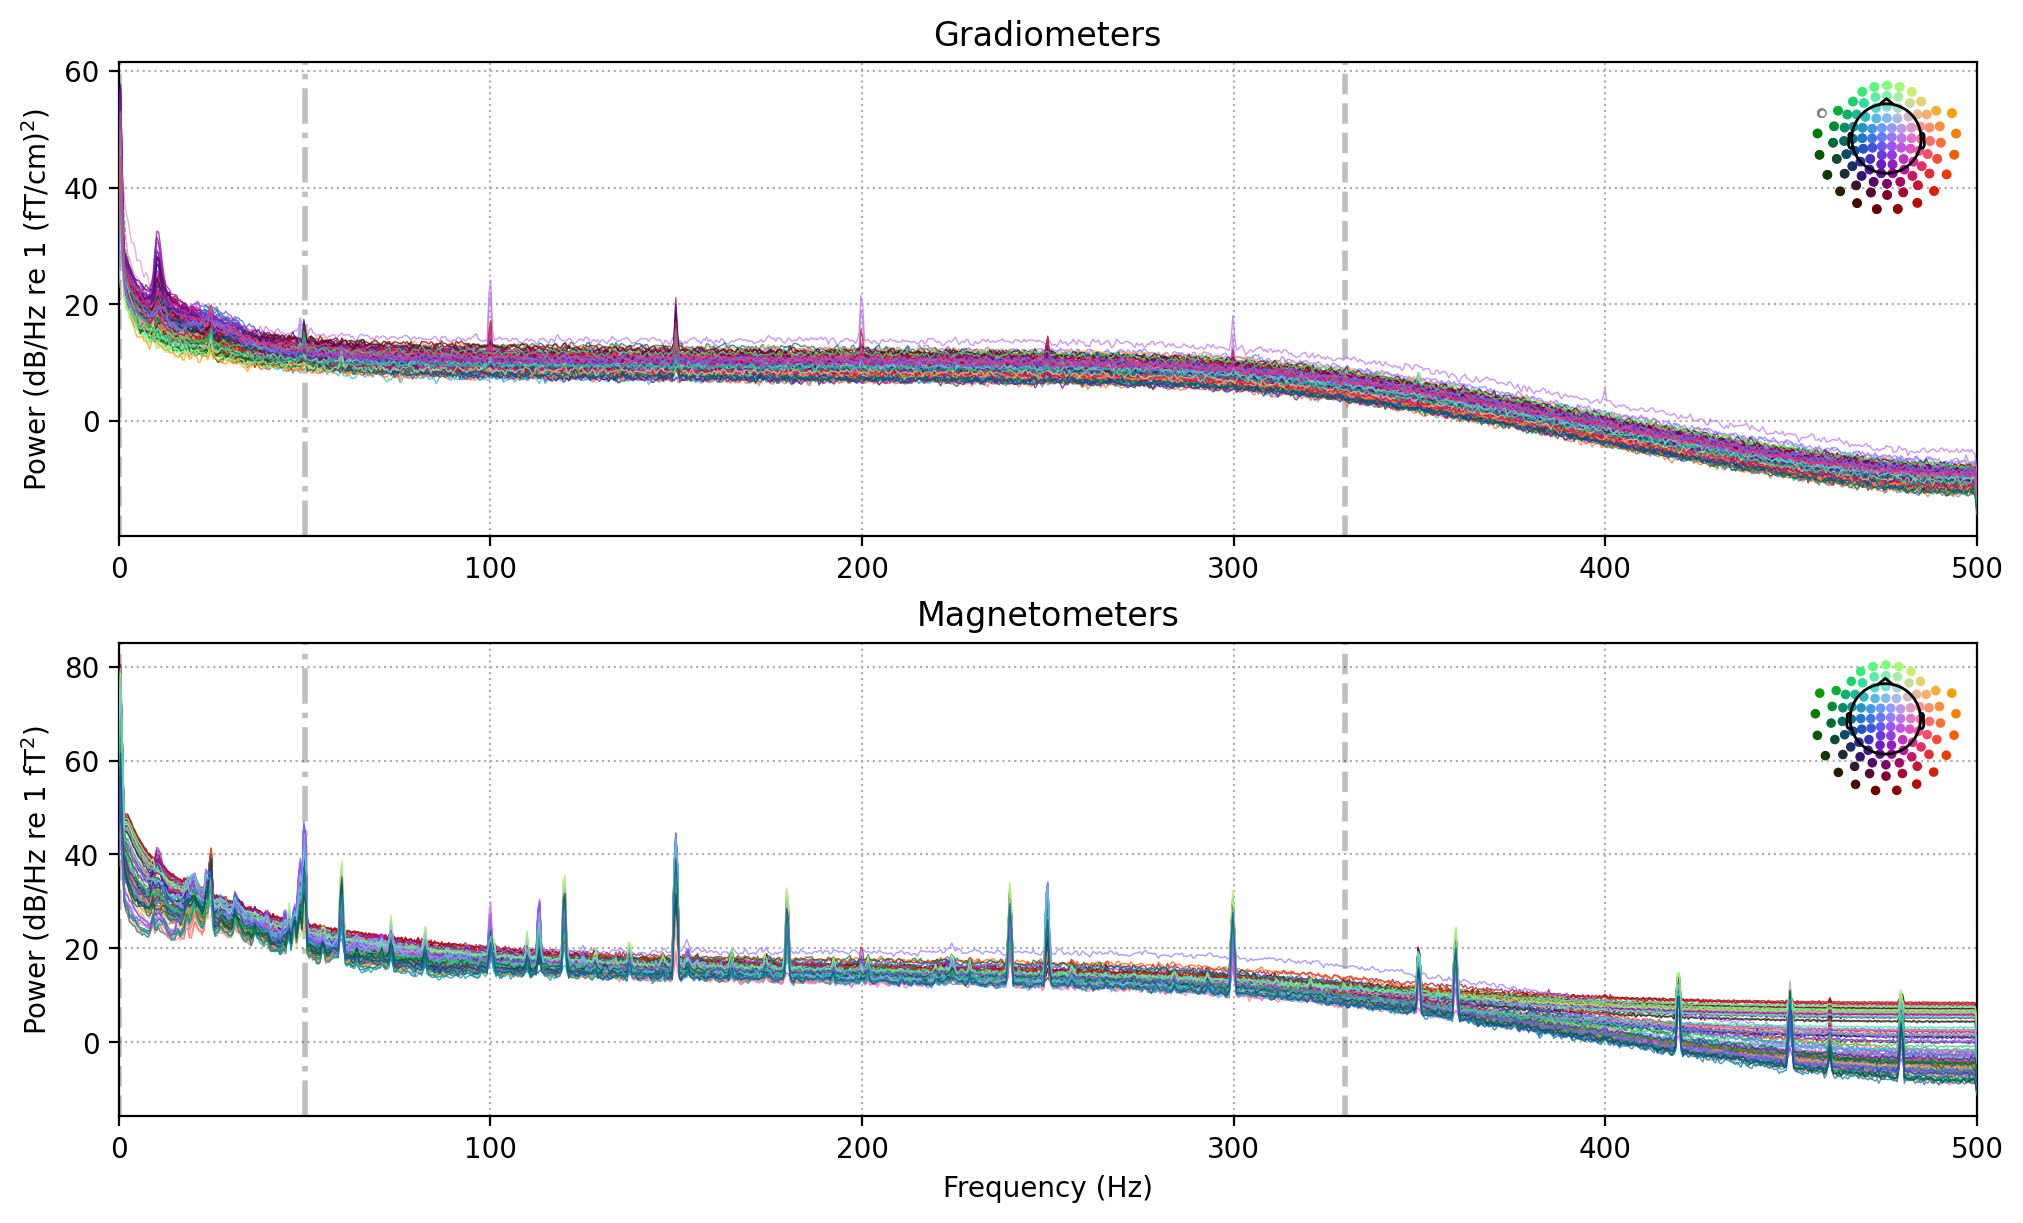

In [5]:
raw.compute_psd().plot()

Using matplotlib as 2D backend.
Effective window size : 2.048 (s)
Plotting power spectral density (dB=True).


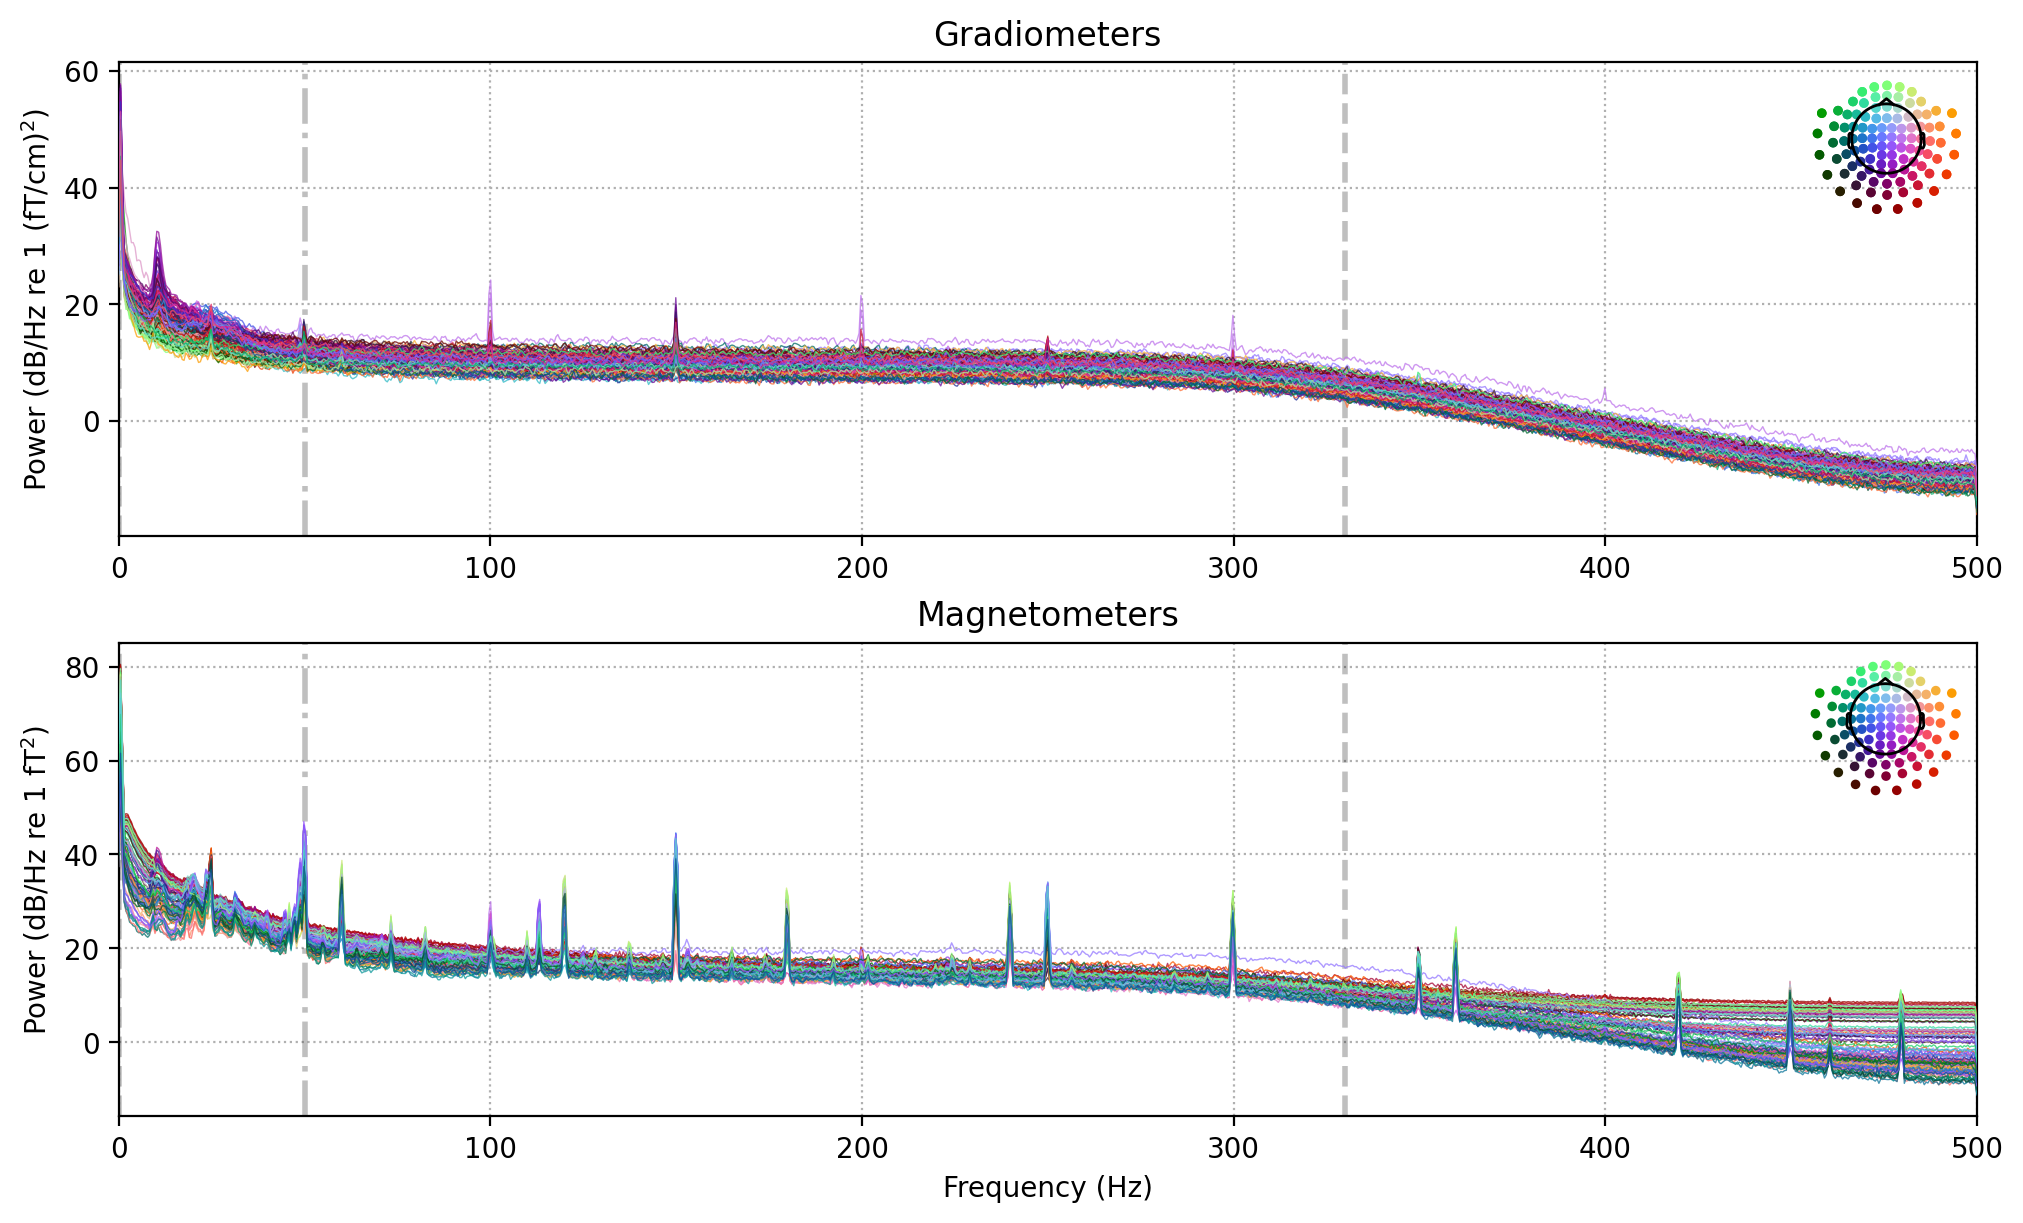

In [3]:
raw.plot()
raw.compute_psd().plot()

In [31]:
mne.pick_types(raw.info, stim=True)

array([326])

In [39]:
events = mne.find_events(raw, stim_channel='STI101')
events

Finding events on: STI101
225 events found on stim channel STI101
Event IDs: [ 96 128 129 130 131 132 133 134 135 144 255]


array([[544918,      0,    255],
       [548011,      0,    128],
       [548680,      0,    129],
       [549688,      0,    144],
       [555960,      0,     96],
       [557419,      0,    128],
       [558088,      0,    129],
       [559120,      0,    144],
       [568353,      0,     96],
       [569804,      0,    128],
       [570471,      0,    129],
       [571489,      0,    144],
       [575009,      0,     96],
       [576585,      0,    128],
       [577252,      0,    129],
       [578754,      0,    130],
       [580221,      0,    131],
       [581722,      0,    132],
       [583224,      0,    133],
       [584191,      0,    144],
       [588837,      0,     96],
       [590613,      0,    128],
       [591280,      0,    129],
       [592765,      0,    130],
       [594300,      0,    131],
       [595284,      0,    144],
       [605835,      0,     96],
       [607452,      0,    128],
       [608120,      0,    129],
       [609104,      0,    144],
       [61

In [41]:
# list of the events types
np.unique(events[:, 2])

array([ 96, 128, 129, 130, 131, 132, 133, 134, 135, 144, 255])

In [42]:
from collections import Counter
Counter(events[:, 2])

Counter({128: 32,
         129: 32,
         144: 32,
         96: 32,
         130: 24,
         131: 24,
         132: 16,
         133: 16,
         134: 8,
         135: 8,
         255: 1})